# Deep Q-Learning (DQN) on Atari Pong

We trained DQN on CartPole and on LunarLander. Now we use the same algorithm on the problem it was invented for: playing an **Atari game from the screen pixels** (Mnih et al., 2013 and 2015). Compared with LunarLander:

* the state is an **image**, so the Q-network is a **convolutional** neural network (CNN);
* one image does not show in which direction the ball moves, so the state is a **stack of the last 4 frames**;
* $\varepsilon$ and the target-network copies are counted in **environment steps** instead of episodes, because a Pong episode can last from about 800 to more than 4000 steps.

The algorithm itself does not change: $\varepsilon$-greedy behaviour policy, **experience replay**, a **target network**, and the Bellman target

$$y = r + \gamma(1-\mathrm{terminated})\max_{a'}Q(s',a';\theta^-).$$

**Running time.** Training needs roughly 1 million steps: about **1–2 hours on an NVIDIA GPU** and many hours on a laptop. Train with the script `03_DQN_Pong_train.py` on a GPU server, copy `dqn_pong_policy.pth` and `dqn_pong_returns.npy` to this folder, and run this notebook with `TRAIN = False` to load them.

**References**

* V. Mnih et al., *Playing Atari with Deep Reinforcement Learning*, 2013 (arXiv:1312.5602).
* V. Mnih et al., *Human-level control through deep reinforcement learning*, Nature 518, 2015.
* M. Lapan, *Deep Reinforcement Learning Hands-On*, Packt, chapter on DQN for Pong (the hyperparameters below follow this fast recipe).

In [1]:
import gymnasium as gym
import numpy as np
import random
import time
from collections import deque

import ale_py
import torch
import torch.nn as nn
from gymnasium.wrappers import AtariPreprocessing, FrameStackObservation
from matplotlib import pyplot as plt

## Configuration

The values below are deliberately kept together so they are easy to inspect and change.

Set `TRAIN = False` to skip training and load the network trained with `03_DQN_Pong_train.py`.

In [2]:
# Training configuration
NUM_EPISODES = 800
MAX_STEPS_PER_EPISODE = 10000
GAMMA = 0.99
LEARNING_RATE = 0.0001
BATCH_SIZE = 32
BUFFER_SIZE = 10000
MIN_BUFFER = 10000
TRAIN_FREQ = 1                    # one gradient step every TRAIN_FREQ environment steps
TARGET_UPDATE_STEPS = 1000       # copy the online network every TARGET_UPDATE_STEPS steps
GRAD_CLIP = 10.0

# Epsilon-greedy exploration schedule (linear in the number of environment steps)
EPSILON_MAX = 1.0
EPSILON_MIN = 0.01
EPSILON_DECAY_STEPS = 150000

STOP_AT_MEAN = 19.0         # stop when the mean of the last 20 training returns reaches this value
EVAL_EPISODES = 10
EVAL_EPSILON = 0.05

SEED = 42

TRAIN = False                 # False: load the network trained on the GPU server
MODEL_PATH = "dqn_pong_policy.pth"
RETURNS_PATH = "dqn_pong_returns.npy"

## Environment

`ALE/Pong-v5` is the Atari 2600 game Pong. The agent controls the green paddle on the right; the opponent is the computer.

* Actions: 6 (`NOOP`, `FIRE`, `RIGHT`, `LEFT`, `RIGHTFIRE`, `LEFTFIRE`; here `RIGHT` moves the paddle up and `LEFT` moves it down).
* Reward: $+1$ when the agent scores a point and $-1$ when the opponent scores. The episode ends when one player reaches 21 points, so the return is between $-21$ and $+21$.

The raw observation is a $210 \times 160$ RGB image. As in the DQN papers, we preprocess it with Gymnasium wrappers:

* `frameskip=1, repeat_action_probability=0.0`: the emulator itself does not skip frames (the wrapper does it) and actions are deterministic;
* `AtariPreprocessing`: up to 30 random *no-op* actions at reset, the agent acts every **4 frames** (the action is repeated in between), grayscale, resized to $84 \times 84$, pixels kept as integers in $[0, 255]$;
* `FrameStackObservation`: the state is the stack of the **last 4 frames**, with shape $(4, 84, 84)$.

In [3]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

gym.register_envs(ale_py)


def make_env():
    """Create Pong with the preprocessing of the DQN papers."""
    env = gym.make(
        "ALE/Pong-v5",
        frameskip=1,
        repeat_action_probability=0.0,
        full_action_space=False,
    )
    env = AtariPreprocessing(
        env,
        noop_max=30,
        frame_skip=4,
        screen_size=84,
        terminal_on_life_loss=False,
        grayscale_obs=True,
        scale_obs=False,
    )
    env = FrameStackObservation(env, stack_size=4)
    return env


env = make_env()
env.action_space.seed(SEED)

state_shape = env.observation_space.shape
action_size = env.action_space.n

print("State shape:", state_shape, env.observation_space.dtype)
print("Action size:", action_size)
print("Actions:", env.unwrapped.get_action_meanings())
print("Device:", device)

A.L.E: Arcade Learning Environment (version 0.12.0+0706845)
[Powered by Stella]


State shape: (4, 84, 84) uint8
Action size: 6
Actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
Device: mps


### What the agent sees

One state after a few random steps: the 4 stacked frames, from the oldest to the newest. Comparing them shows how the ball and the paddles move.

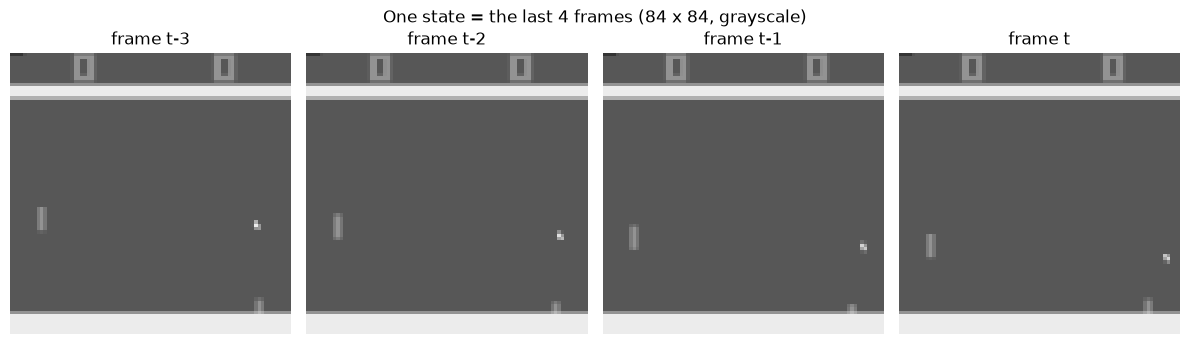

In [4]:
show_env = make_env()
state, info = show_env.reset(seed=SEED)
for _ in range(60):
    state, reward, terminated, truncated, info = show_env.step(show_env.action_space.sample())
show_env.close()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.5))
for i in range(4):
    axes[i].imshow(state[i], cmap="gray", vmin=0, vmax=255)
    axes[i].set_title(f"frame t-{3 - i}" if i < 3 else "frame t")
    axes[i].axis("off")
fig.suptitle("One state = the last 4 frames (84 x 84, grayscale)")
plt.tight_layout()
plt.show()

## Q-network

The "Nature" convolutional network (Mnih et al., 2015). It receives the 4 stacked frames and returns one action-value per action:

| Layer | Output shape |
|---|---|
| input: 4 frames | $4 \times 84 \times 84$ |
| Conv $4 \to 32$, $8 \times 8$, stride 4, ReLU | $32 \times 20 \times 20$ |
| Conv $32 \to 64$, $4 \times 4$, stride 2, ReLU | $64 \times 9 \times 9$ |
| Conv $64 \to 64$, $3 \times 3$, stride 1, ReLU | $64 \times 7 \times 7$ |
| Fully connected $3136 \to 512$, ReLU | $512$ |
| Fully connected $512 \to 6$ | $6$ Q-values |

The states are stored as integers in $[0, 255]$ (`uint8`, 1 byte per pixel). We convert them to floats in $[0, 1]$ **inside** `forward()`, so the replay buffer needs 4 times less memory than with `float32`.

In [5]:
class QNetwork(nn.Module):
    """Map 4 stacked 84x84 frames to one Q-value per action."""

    def __init__(self, action_size):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(4, 32, kernel_size=8, stride=4),
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2),
            nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=1),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 512),
            nn.ReLU(),
            nn.Linear(512, action_size),
        )

    def forward(self, state):
        # uint8 pixels in [0, 255] -> floats in [0, 1]
        return self.net(state.float() / 255.0)

In [6]:
# Online network: updated by gradient descent
q_net = QNetwork(action_size).to(device)

# Target network: supplies stable Bellman targets
target_net = QNetwork(action_size).to(device)
target_net.load_state_dict(q_net.state_dict())
target_net.eval()

optimizer = torch.optim.Adam(q_net.parameters(), lr=LEARNING_RATE)
loss_fn = nn.MSELoss()
replay_buffer = deque(maxlen=BUFFER_SIZE)

print("Number of parameters:", sum(p.numel() for p in q_net.parameters()))

Number of parameters: 1687206


## Replay buffer and policy helper

The replay buffer stores transitions $(s,a,r,s',\mathrm{terminated})$. The behaviour policy explores with probability $\varepsilon$ and otherwise chooses the action with the largest predicted Q-value.

Two differences with LunarLander:

* $\varepsilon$ decreases **linearly with the number of environment steps**, from `EPSILON_MAX` to `EPSILON_MIN` in `EPSILON_DECAY_STEPS` steps, and then stays constant.
* We do **not** call `.copy()` when storing the states. The frame-stack wrapper returns a new array at every step, so nothing overwrites a stored state, and the `next_state` of one transition is the same array as the `state` of the next one. Storing it once instead of twice halves the memory: each state has $4 \times 84 \times 84 \approx 28$ kB.

In [7]:
def epsilon_by_step(step):
    """Linear decay from EPSILON_MAX to EPSILON_MIN, then constant."""
    fraction = min(step / EPSILON_DECAY_STEPS, 1.0)
    return EPSILON_MAX + fraction * (EPSILON_MIN - EPSILON_MAX)


def epsilon_greedy(state, epsilon):
    """Choose a random action or the action with the largest Q-value."""
    if random.random() < epsilon:
        return env.action_space.sample()

    # The state stays uint8; the network converts it to floats
    state_tensor = torch.as_tensor(state, device=device).unsqueeze(0)

    with torch.no_grad():
        q_values = q_net(state_tensor)

    return int(q_values.argmax(dim=1).item())


for step in [0, EPSILON_DECAY_STEPS // 2, EPSILON_DECAY_STEPS, 2 * EPSILON_DECAY_STEPS]:
    print(f"epsilon after {step:7d} steps: {epsilon_by_step(step):.3f}")

epsilon after       0 steps: 1.000
epsilon after   75000 steps: 0.505
epsilon after  150000 steps: 0.010
epsilon after  300000 steps: 0.010


## Learning step

For each sampled transition, DQN fits the online network to the target

$$y = r + \gamma(1-\mathrm{terminated})\max_{a'}Q(s',a';\theta^-).$$

`terminated` is true when one player reaches 21 points. `truncated` only means that a time limit was reached, so it does not remove the bootstrap term. The target is computed without gradients because only the online prediction $Q(s,a;\theta)$ is being fitted.

The code is the same as for LunarLander, except that the states are sent to the device as `uint8`.

In [8]:
def train_step():
    """Perform one DQN update from a random replay minibatch."""
    if len(replay_buffer) < MIN_BUFFER:
        return None

    batch = random.sample(replay_buffer, BATCH_SIZE)
    states, actions, rewards, next_states, terminated = zip(*batch)

    states = torch.as_tensor(np.array(states), device=device)
    actions = torch.as_tensor(
        actions, dtype=torch.int64, device=device
    ).unsqueeze(1)
    rewards = torch.as_tensor(
        rewards, dtype=torch.float32, device=device
    ).unsqueeze(1)
    next_states = torch.as_tensor(np.array(next_states), device=device)
    terminated = torch.as_tensor(
        terminated, dtype=torch.float32, device=device
    ).unsqueeze(1)

    all_q_values = q_net(states)
    selected_q_values = all_q_values.gather(1, actions)

    with torch.no_grad():
        all_next_q_values = target_net(next_states)
        max_next_q_values = all_next_q_values.max(dim=1, keepdim=True)[0]
        targets = rewards + GAMMA * max_next_q_values * (1.0 - terminated)

    loss = loss_fn(selected_q_values, targets)

    optimizer.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(q_net.parameters(), GRAD_CLIP)
    optimizer.step()

    return loss.item()

### Check the tensor shapes

A minibatch contains 32 states, each made of 4 frames of $84 \times 84$ pixels. The network returns six Q-values per state, while the chosen Q-values and Bellman targets each contain one value per transition.

In [9]:
example_states = torch.zeros((BATCH_SIZE, *state_shape), dtype=torch.uint8, device=device)
example_actions = torch.zeros((BATCH_SIZE, 1), dtype=torch.int64, device=device)
example_q_values = q_net(example_states)
example_selected_q_values = example_q_values.gather(1, example_actions)
example_targets = torch.zeros((BATCH_SIZE, 1), device=device)

print("States:           ", tuple(example_states.shape))
print("All Q-values:     ", tuple(example_q_values.shape))
print("Selected Q-values:", tuple(example_selected_q_values.shape))
print("Targets:          ", tuple(example_targets.shape))

States:            (32, 4, 84, 84)
All Q-values:      (32, 6)
Selected Q-values: (32, 1)
Targets:           (32, 1)


## Training

For every environment step we store one transition and, once the replay buffer contains `MIN_BUFFER` transitions, perform one gradient update every `TRAIN_FREQ` steps. Every `TARGET_UPDATE_STEPS` steps the target network is replaced by a copy of the online network. Training stops early when the mean of the last 20 returns reaches `STOP_AT_MEAN`.

With `TRAIN = False` this cell loads the network and the returns saved by `03_DQN_Pong_train.py` instead.

In [11]:
if TRAIN:
    rewards_all_episodes = []
    steps_all_episodes = []
    losses = []
    total_steps = 0

    start_time = time.time()

    for episode in range(NUM_EPISODES):
        if episode == 0:
            state, info = env.reset(seed=SEED)
        else:
            state, info = env.reset()

        episode_reward = 0.0
        steps_taken = 0

        for step in range(MAX_STEPS_PER_EPISODE):
            epsilon = epsilon_by_step(total_steps)
            action = epsilon_greedy(state, epsilon)
            next_state, reward, terminated, truncated, info = env.step(action)
            total_steps += 1

            # No .copy(): the wrapper returns a new array at every step
            replay_buffer.append((
                state,
                action,
                reward,
                next_state,
                float(terminated),
            ))

            if total_steps % TRAIN_FREQ == 0:
                loss = train_step()
                if loss is not None:
                    losses.append(loss)

            if total_steps % TARGET_UPDATE_STEPS == 0:
                target_net.load_state_dict(q_net.state_dict())

            state = next_state
            episode_reward += reward
            steps_taken = step + 1

            if terminated or truncated:
                break

        rewards_all_episodes.append(episode_reward)
        steps_all_episodes.append(steps_taken)
        recent_mean = np.mean(rewards_all_episodes[-20:])

        if episode == 0 or (episode + 1) % 10 == 0:
            speed = total_steps / (time.time() - start_time)
            print(
                f"Episode {episode + 1:3d}: "
                f"reward={episode_reward:5.0f}, "
                f"mean20={recent_mean:6.1f}, "
                f"epsilon={epsilon:.3f}, "
                f"steps={total_steps}, "
                f"speed={speed:.0f} steps/s"
            )

        if len(rewards_all_episodes) >= 20 and recent_mean >= STOP_AT_MEAN:
            print(f"Episode {episode + 1}: mean20={recent_mean:.1f} >= {STOP_AT_MEAN}, stopping.")
            break

    training_minutes = (time.time() - start_time) / 60
    print(f"Training time: {training_minutes:.2f} minutes")
    print(f"Environment steps: {total_steps}")
    print(f"Number of elements in replay buffer: {len(replay_buffer)}")
    print(f"NN training updates: {len(losses)}")
else:
    q_net.load_state_dict(torch.load(MODEL_PATH, map_location=device, weights_only=True))
    rewards_all_episodes = list(np.load(RETURNS_PATH))
    print(f"Loaded {MODEL_PATH} and {len(rewards_all_episodes)} training returns from {RETURNS_PATH}")

Loaded dqn_pong_policy.pth and 267 training returns from dqn_pong_returns.npy


## Learning curves

A random agent loses about 21–0, so the curve starts near $-21$. A return of $+21$ means that the agent won every point.

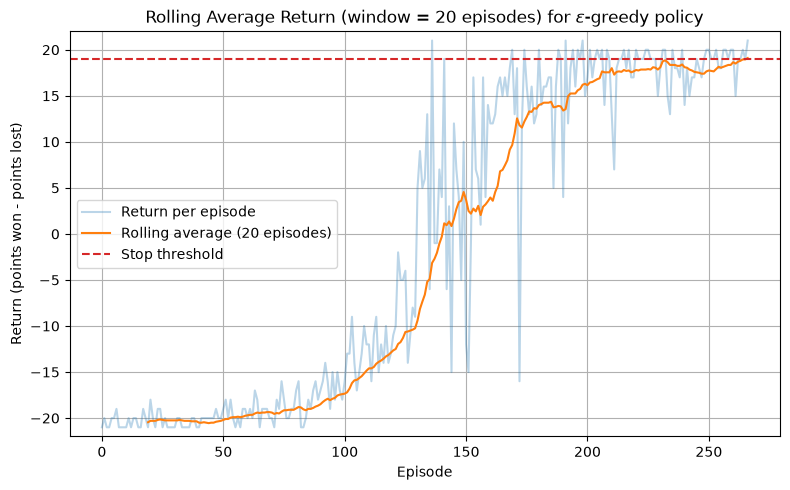

In [12]:
window = 20

plt.figure(figsize=(8, 5))
plt.plot(rewards_all_episodes, alpha=0.3, label="Return per episode")
if len(rewards_all_episodes) >= window:
    rolling_rewards = np.convolve(
        np.array(rewards_all_episodes),
        np.ones(window) / window,
        mode="valid",
    )
    plt.plot(np.arange(window - 1, len(rewards_all_episodes)), rolling_rewards, label=f"Rolling average ({window} episodes)")
plt.axhline(STOP_AT_MEAN, color="tab:red", linestyle="--", label="Stop threshold")
plt.xlabel("Episode")
plt.ylabel("Return (points won - points lost)")
plt.ylim(-22, 22)
plt.title(fr"Rolling Average Return (window = {window} episodes) for $\varepsilon$-greedy policy")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

## Evaluate the policy

Training uses exploration, so its returns do not directly measure the final policy. As in the DQN papers, we evaluate Pong with a small $\varepsilon = 0.05$ instead of $\varepsilon = 0$: the game is deterministic, and a fully greedy agent can get stuck repeating the same rally forever.

In [13]:
q_net.eval()
evaluation_returns = []

for evaluation_episode in range(EVAL_EPISODES):
    state, info = env.reset(seed=SEED + 1000 + evaluation_episode)
    episode_return = 0.0

    for step in range(MAX_STEPS_PER_EPISODE):
        action = epsilon_greedy(state, epsilon=EVAL_EPSILON)
        state, reward, terminated, truncated, info = env.step(action)
        episode_return += reward

        if terminated or truncated:
            break

    evaluation_returns.append(episode_return)

evaluation_returns = np.array(evaluation_returns)
mean_return = evaluation_returns.mean()

print(f"Mean return:     {mean_return:.2f}")
print(f"Standard dev.:   {evaluation_returns.std():.2f}")
print(f"Minimum return:  {evaluation_returns.min():.0f}")
print(f"Maximum return:  {evaluation_returns.max():.0f}")

Mean return:     16.90
Standard dev.:   4.04
Minimum return:  9
Maximum return:  21


## One game

Record one game and plot the score of each player during the game. A good agent wins its points steadily while the opponent scores few.

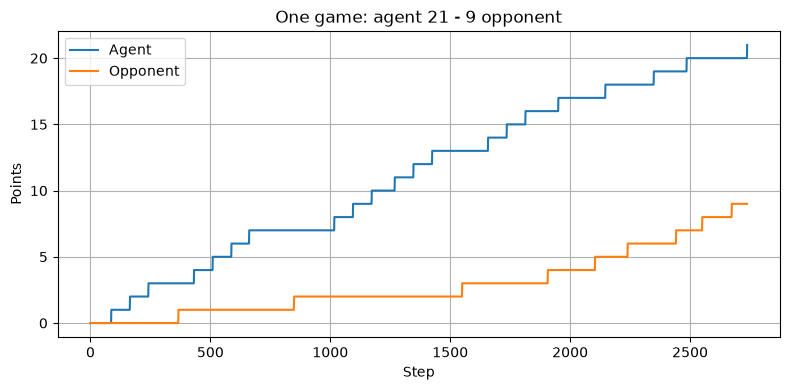

Final score: agent 21 - 9 opponent (2738 steps)


In [14]:
state, info = env.reset(seed=SEED + 2000)
agent_points = [0]
opponent_points = [0]

for step in range(MAX_STEPS_PER_EPISODE):
    action = epsilon_greedy(state, epsilon=EVAL_EPSILON)
    state, reward, terminated, truncated, info = env.step(action)
    agent_points.append(agent_points[-1] + (reward > 0))
    opponent_points.append(opponent_points[-1] + (reward < 0))

    if terminated or truncated:
        break

plt.figure(figsize=(8, 4))
plt.plot(agent_points, label="Agent")
plt.plot(opponent_points, label="Opponent")
plt.xlabel("Step")
plt.ylabel("Points")
plt.title(f"One game: agent {agent_points[-1]} - {opponent_points[-1]} opponent")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

print(f"Final score: agent {agent_points[-1]} - {opponent_points[-1]} opponent ({step + 1} steps)")

## Save the trained network

The weights are moved to the CPU before saving, so the file can be loaded on any machine (with or without a GPU). The same `QNetwork` architecture must be created before these weights are loaded later. To watch the agent play, run `python run_dqn_pong_policy.py`.

In [ ]:
if TRAIN:
    torch.save({name: w.cpu() for name, w in q_net.state_dict().items()}, MODEL_PATH)
    np.save(RETURNS_PATH, np.array(rewards_all_episodes))
    print("Saved:", MODEL_PATH, "and", RETURNS_PATH)

# Check that the saved state dictionary can be loaded.
saved_weights = torch.load(MODEL_PATH, map_location=device, weights_only=True)
check_net = QNetwork(action_size).to(device)
check_net.load_state_dict(saved_weights)
check_net.eval()

print("Saved and reloaded:", MODEL_PATH)
env.close()